<a href="https://colab.research.google.com/github/majax23/Uczenie-glebokie-do-rozpoznawania-obiektow-MS/blob/main/Maja_Swiniarska_LAB2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Laboratorium 2**


## Import bibliotek i wybór urządzenia


In [2]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "| urządzenie:", device)

PyTorch: 2.11.0+cu130 | urządzenie: cuda


##Transformacje danych
Definiuje dwie transformacje:
- `test_tf` – tylko ToTensor + normalizacja (czyste dane: baseline, walidacja, test),
- `train_tf_aug` – to samo + `RandomHorizontalFlip` (**augmentacja, tylko dla zbioru treningowego**).

In [6]:
mean, std = 0.2860, 0.3530   #średnia i odchylenie FashionMNIST

test_tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((mean,), (std,)),
])

train_tf_aug = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((mean,), (std,)),
])

##Zbiory danych, podział train/val i DataLoadery
Zbiór treningowy: 54 000

Walidacja: 6 000.

`train_eval_dl` – czysty (bez augmentacji) loader treningowy do uczciwego liczenia straty/accuracy na treningu.

In [7]:
train_plain = torchvision.datasets.FashionMNIST("./data", train=True, download=True, transform=test_tf)
train_aug   = torchvision.datasets.FashionMNIST("./data", train=True, download=True, transform=train_tf_aug)
test_ds     = torchvision.datasets.FashionMNIST("./data", train=False, download=True, transform=test_tf)

#stratyfikowany podział po 1000 przykładów z każdej klasy do walidacji
g = torch.Generator().manual_seed(0)
targets = train_plain.targets
val_idx, tr_idx = [], []
for c in range(10):
    idx = (targets == c).nonzero(as_tuple=True)[0]
    idx = idx[torch.randperm(len(idx), generator=g)]
    val_idx += idx[:1000].tolist()
    tr_idx  += idx[1000:].tolist()

train_ds_plain = Subset(train_plain, tr_idx)   #trening bez augmentacji
train_ds_aug   = Subset(train_aug,   tr_idx)   #trening z augmentacją
val_ds         = Subset(train_plain, val_idx)  #walidacja

BATCH = 128
val_dl        = DataLoader(val_ds, batch_size=256, shuffle=False)
test_dl       = DataLoader(test_ds, batch_size=256, shuffle=False)
train_eval_dl = DataLoader(train_ds_plain, batch_size=256, shuffle=False)  #czysty trening do pomiaru

def make_train_dl(ds, seed=0):
    #powtarzalna kolejność próbek
    return DataLoader(ds, batch_size=BATCH, shuffle=True,
                      generator=torch.Generator().manual_seed(seed))

print(f"train: {len(train_ds_plain)} | val: {len(val_ds)} | test: {len(test_ds)}")

100%|██████████| 26.4M/26.4M [00:02<00:00, 12.1MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 206kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.78MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 28.3MB/s]


train: 50000 | val: 10000 | test: 10000


##Model (MLP z opcjonalnym BatchNorm i Dropout) oraz funkcja `evaluate`
`MLP` – sieć w pełni połączona 784→256→128→10; parametry `use_bn` (BatchNorm) i `p_drop` (Dropout) włączają regularyzację.
`evaluate` – zwraca średnią stratę i accuracy na zadanym DataLoaderze (tryb `eval`, bez gradientów).

In [8]:
class MLP(nn.Module):
    def __init__(self, in_dim=28*28, hidden=(256, 128), n_classes=10, use_bn=False, p_drop=0.0):
        super().__init__()
        layers, d = [nn.Flatten()], in_dim
        for h in hidden:
            layers.append(nn.Linear(d, h))
            if use_bn:
                layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU())
            if p_drop > 0:
                layers.append(nn.Dropout(p_drop))
            d = h
        layers.append(nn.Linear(d, n_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def evaluate(model, dl):
    model.eval()
    correct = total = 0
    loss_sum = 0.0
    crit = nn.CrossEntropyLoss(reduction="sum")
    with torch.no_grad():
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss_sum += crit(out, yb).item()
            correct += (out.argmax(1) == yb).sum().item()
            total += yb.numel()
    return loss_sum / total, correct / total

##Funkcja treningowa


In [9]:
def run_training(model, train_dl, epochs=15, lr=1e-3, weight_decay=0.0,
                 optimizer="adam", use_scheduler=False, verbose=False):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()

    if optimizer == "adam":
        opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    elif optimizer == "adamw":
        opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    else:
        raise ValueError(f"Nieznany optymalizator: {optimizer}")

    sched = (torch.optim.lr_scheduler.StepLR(opt, step_size=max(1, epochs // 3), gamma=0.5)
             if use_scheduler else None)

    hist = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc", "test_loss", "test_acc"]}

    for epoch in range(1, epochs + 1):
        model.train()
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            opt.step()
        if sched:
            sched.step()

        #pomiar na czystych danych
        tl, ta = evaluate(model, train_eval_dl)
        vl, va = evaluate(model, val_dl)
        sl, sa = evaluate(model, test_dl)
        for k, v in zip(hist.keys(), [tl, ta, vl, va, sl, sa]):
            hist[k].append(v)

        if verbose:
            print(f"Epoka {epoch:2d} | train {tl:.3f}/{ta*100:.2f}% | val {vl:.3f}/{va*100:.2f}% | test {sl:.3f}/{sa*100:.2f}%")
    return hist

##Baseline i pojedyncze ulepszenia


In [11]:
EPOCHS = 15
LR = 1e-3

BASE = dict(aug=False, p_drop=0.0, bn=False, opt="adam", wd=0.0, sched=False)


SINGLE = {
    "Baseline":               {},
    "A: Augmentacja (flip)":  dict(aug=True),
    "B: Dropout (p=0.2)":     dict(p_drop=0.2),
    "C: BatchNorm":           dict(bn=True),
    "D: AdamW (wd=1e-2)":     dict(opt="adamw", wd=1e-2),
    "E: Scheduler (StepLR)":  dict(sched=True),
}

def run_config(name, overrides, lr=LR, epochs=EPOCHS):
    cfg = {**BASE, **overrides}
    torch.manual_seed(0)
    model = MLP(p_drop=cfg["p_drop"], use_bn=cfg["bn"])
    dl = make_train_dl(train_ds_aug if cfg["aug"] else train_ds_plain, seed=0)
    hist = run_training(model, dl, epochs=epochs, lr=lr, weight_decay=cfg["wd"],
                        optimizer=cfg["opt"], use_scheduler=cfg["sched"])
    return {"name": name, "overrides": overrides, "hist": hist}

runs = {}
for name, ov in SINGLE.items():
    runs[name] = run_config(name, ov)
    h = runs[name]["hist"]
    print(f"{name:<24} | val acc {h['val_acc'][-1]*100:.2f}% | test acc {h['test_acc'][-1]*100:.2f}%")

Baseline                 | val acc 89.67% | test acc 88.54%
A: Augmentacja (flip)    | val acc 89.41% | test acc 88.84%
B: Dropout (p=0.2)       | val acc 89.48% | test acc 88.72%
C: BatchNorm             | val acc 88.57% | test acc 88.10%
D: AdamW (wd=1e-2)       | val acc 89.59% | test acc 89.07%
E: Scheduler (StepLR)    | val acc 90.14% | test acc 89.58%


##Najlepsza kombinacja ulepszeń


In [12]:
base_val = runs["Baseline"]["hist"]["val_acc"][-1]
good = [n for n in SINGLE if n != "Baseline" and runs[n]["hist"]["val_acc"][-1] > base_val]
print("Ulepszenia, które poprawiły walidację:", good if good else "brak")

if len(good) >= 2:
    combo_ov = {}
    for n in good:
        combo_ov.update(SINGLE[n])
    combo_name = "Kombinacja: " + " + ".join(n.split(":")[0] for n in good)
    runs[combo_name] = run_config(combo_name, combo_ov)
    h = runs[combo_name]["hist"]
    print(f"{combo_name:<24} | val acc {h['val_acc'][-1]*100:.2f}% | test acc {h['test_acc'][-1]*100:.2f}%")

#najlepsza konfiguracja (najwyższe accuracy na walidacji)
best_name = max(runs, key=lambda n: runs[n]["hist"]["val_acc"][-1])
print("\nNajlepsza konfiguracja (wg walidacji):", best_name)

Ulepszenia, które poprawiły walidację: ['E: Scheduler (StepLR)']

Najlepsza konfiguracja (wg walidacji): E: Scheduler (StepLR)


##Tabela wyników: accuracy i przerwa train–test


In [13]:
def summary(name):
    h = runs[name]["hist"]
    return dict(
        name=name,
        val_acc=h["val_acc"][-1] * 100,
        test_acc=h["test_acc"][-1] * 100,
        train_acc=h["train_acc"][-1] * 100,
        gap_acc=(h["train_acc"][-1] - h["test_acc"][-1]) * 100,
        gap_loss=h["test_loss"][-1] - h["train_loss"][-1],
    )

rows = [summary(n) for n in runs]
line = "=" * 100
print(line)
print(f"{'Konfiguracja':<28}|{'Acc val':>9} |{'Acc test':>9} |{'Acc train':>10} |{'Przerwa acc [pp]':>17} |{'Przerwa loss':>13}")
print("-" * 100)
for r in rows:
    mark = "  <-- najlepsza" if r["name"] == best_name else ""
    print(f"{r['name']:<28}|{r['val_acc']:>8.2f}% |{r['test_acc']:>8.2f}% |{r['train_acc']:>9.2f}% |{r['gap_acc']:>17.2f} |{r['gap_loss']:>13.4f}{mark}")
print(line)

Konfiguracja                |  Acc val | Acc test | Acc train | Przerwa acc [pp] | Przerwa loss
----------------------------------------------------------------------------------------------------
Baseline                    |   89.67% |   88.54% |    94.81% |             6.27 |       0.2299
A: Augmentacja (flip)       |   89.41% |   88.84% |    93.43% |             4.59 |       0.1552
B: Dropout (p=0.2)          |   89.48% |   88.72% |    92.94% |             4.22 |       0.1409
C: BatchNorm                |   88.57% |   88.10% |    94.85% |             6.75 |       0.2569
D: AdamW (wd=1e-2)          |   89.59% |   89.07% |    95.00% |             5.93 |       0.2274
E: Scheduler (StepLR)       |   90.14% |   89.58% |    95.28% |             5.70 |       0.2116  <-- najlepsza


##Krzywe uczenia


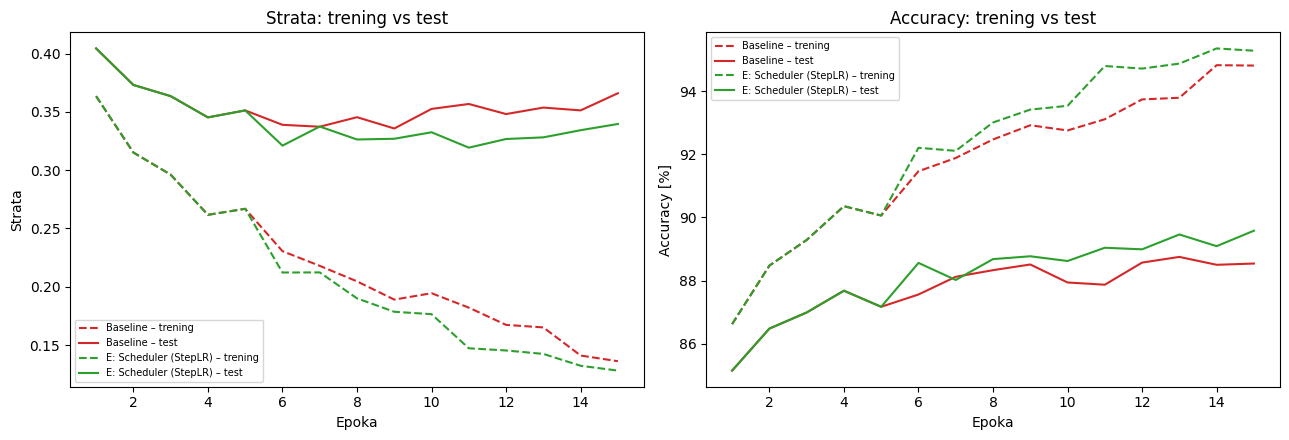

In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for name, c in [("Baseline", "tab:red"), (best_name, "tab:green")]:
    h = runs[name]["hist"]
    ep = range(1, len(h["train_loss"]) + 1)
    ax1.plot(ep, h["train_loss"], "--", color=c, label=f"{name} – trening")
    ax1.plot(ep, h["test_loss"],  "-",  color=c, label=f"{name} – test")
    ax2.plot(ep, [a*100 for a in h["train_acc"]], "--", color=c, label=f"{name} – trening")
    ax2.plot(ep, [a*100 for a in h["test_acc"]],  "-",  color=c, label=f"{name} – test")

ax1.set_xlabel("Epoka"); ax1.set_ylabel("Strata"); ax1.set_title("Strata: trening vs test"); ax1.legend(fontsize=7)
ax2.set_xlabel("Epoka"); ax2.set_ylabel("Accuracy [%]"); ax2.set_title("Accuracy: trening vs test"); ax2.legend(fontsize=7)
plt.tight_layout(); plt.show()

##Porównanie przerwy train–test i komentarz


In [20]:
b, w = summary("Baseline"), summary(best_name)
print(f"Baseline : acc test {b['test_acc']:.2f}% | przerwa acc {b['gap_acc']:.2f} pp | przerwa loss {b['gap_loss']:.4f}")
print(f"Najlepsza: acc test {w['test_acc']:.2f}% | przerwa acc {w['gap_acc']:.2f} pp | przerwa loss {w['gap_loss']:.4f}  ({best_name})")

d_acc, d_loss = b["gap_acc"] - w["gap_acc"], b["gap_loss"] - w["gap_loss"]
if best_name == "Baseline":
    print("\nŻadne ulepszenie nie przebiło baseline na walidacji – przeuczenie nie zostało zmniejszone.")
elif d_loss > 0:
    print(f"\nPrzerwa w stracie zmalała o {d_loss:.4f} ({d_loss/b['gap_loss']*100:.0f}%), w accuracy o {d_acc:.2f} pp "
          f"- przeuczenie zostało zmniejszone, accuracy testowe zmieniło się o {w['test_acc']-b['test_acc']:+.2f} pp.")
else:
    print("\nPrzerwa w stracie nie zmalała – regularyzacja nie ograniczyła przeuczenia w tej konfiguracji.")
print("Uwaga: pojedynczy seed – różnice rzędu ~0.2–0.3 pp accuracy mogą mieścić się w szumie.")

Baseline : acc test 88.54% | przerwa acc 6.27 pp | przerwa loss 0.2299
Najlepsza: acc test 89.58% | przerwa acc 5.70 pp | przerwa loss 0.2116  (E: Scheduler (StepLR))

Przerwa w stracie zmalała o 0.0183 (8%), w accuracy o 0.57 pp - przeuczenie zostało zmniejszone, accuracy testowe zmieniło się o +1.04 pp.
Uwaga: pojedynczy seed – różnice rzędu ~0.2–0.3 pp accuracy mogą mieścić się w szumie.


## *Early stopping


In [16]:
def early_stop(val_loss, patience=3, min_delta=1e-4):
    best, best_ep, bad = float("inf"), 0, 0
    for i, v in enumerate(val_loss, 1):
        if v < best - min_delta:
            best, best_ep, bad = v, i, 0
        else:
            bad += 1
            if bad >= patience:
                return best_ep, i
    return best_ep, len(val_loss)

for name in ["Baseline", best_name]:
    h = runs[name]["hist"]
    be, se = early_stop(h["val_loss"], patience=3)
    print(f"{name:<24} | stop w epoce {se:2d} | najlepsza epoka {be:2d} | "
          f"acc test {h['test_acc'][be-1]*100:.2f}% | przerwa loss {h['test_loss'][be-1]-h['train_loss'][be-1]:.4f}")

Baseline                 | stop w epoce 10 | najlepsza epoka  7 | acc test 88.12% | przerwa loss 0.1193
E: Scheduler (StepLR)    | stop w epoce 14 | najlepsza epoka 11 | acc test 89.04% | przerwa loss 0.1721


##*Przegląd współczynnika uczenia


lr=0.1     | val acc 10.00% | test acc 10.00%
lr=0.01    | val acc 87.20% | test acc 86.50%
lr=0.001   | val acc 89.67% | test acc 88.54%
lr=0.0001  | val acc 88.46% | test acc 87.40%


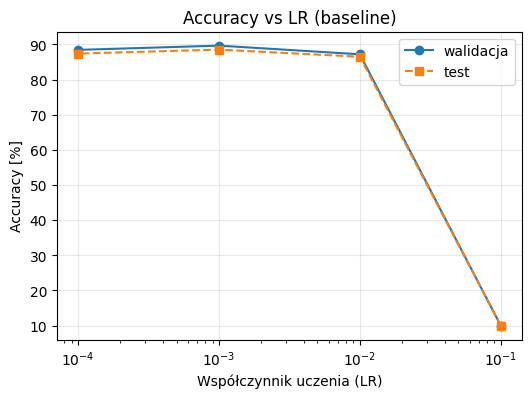

In [18]:
lrs = [1e-1, 1e-2, 1e-3, 1e-4]
lr_val, lr_test = [], []
for lr in lrs:
    r = run_config(f"Baseline lr={lr:g}", {}, lr=lr)
    lr_val.append(r["hist"]["val_acc"][-1] * 100)
    lr_test.append(r["hist"]["test_acc"][-1] * 100)
    print(f"lr={lr:<7g} | val acc {lr_val[-1]:.2f}% | test acc {lr_test[-1]:.2f}%")

plt.figure(figsize=(6, 4))
plt.semilogx(lrs, lr_val, "o-", label="walidacja")
plt.semilogx(lrs, lr_test, "s--", label="test")
plt.xlabel("Współczynnik uczenia (LR)"); plt.ylabel("Accuracy [%]")
plt.title("Accuracy vs LR (baseline)"); plt.grid(alpha=.3); plt.legend(); plt.show()